# Dependencies (for venv)

In [97]:
pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


# Generate the dataset

In [98]:
import random
import torch

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')   
# device = torch.device('cpu')
torch.set_default_device(device)

print(torch.get_default_device())

cuda:0


In [99]:
def generate_objects(N=3, block_size=0.2, initial_tower=True):
    # 1. Generate random order for the goals
    idx_goals = [i for i in range(0, N)]
    # random.shuffle(idx_goals)

    # 2. Generate initial order for the blocks by inverting the order of goals
    idx_objs = idx_goals[::-1]

    # 3. Generate goals
    # https://www.generationrobots.com/media/panda-franka-emika-datasheet.pdf
    # according to the datasheet, the Franka Panda can reach in an area of 0.855 [m] around itself
    max_reach_dist = 0.7 # [m]

    # select a random (x,y) position for the goal.
    x_goal = random.random() * max_reach_dist
    y_goal = random.random() * max_reach_dist

    pos_goals = [(x_goal, y_goal, i*block_size) for i in range(0, N)]

    # Generate initial positions
    if initial_tower:
        x_obj = random.random() * max_reach_dist
        y_obj = random.random() * max_reach_dist

        pos_objects = [(x_obj, y_obj, i*block_size) for i in range(0, N)]
    else:
        pos_objects = [(random.random() * max_reach_dist, random.random() * max_reach_dist, i*block_size) for i in range(0, N)]

    goals = {}
    objects = {}
    for i in range(0, N):
        goals[idx_goals[i]] = pos_goals[i]
        objects[idx_objs[i]] = pos_objects[i]

    # print(f"goals (in desired order of final stacking):\n{goals}")
    # print(f"initial object positions (in order of stacking):\n{objects}")

    return objects, goals, idx_objs, idx_goals


In [100]:
# Now solve the stacking problem by taking the highest block in the objects tower (last in order)
# and putting it into the lowest available goal (first in order)

# build the state vector, ordered nodes with categorical, position and binary features, followed by ordered goals with the same features
def build_state(objects, goals):
    s = []
    N = len(objects)
    for n in range(0, N):
        # one hot encode of blocks (all nodes are either blocks or goals, all objects are blocks)
        s.append(1)
        s.append(0)

        # binary encode of whether block is in goal
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        full_correct = int(objects[n] == goals[n])
        s.append(full_correct)
        # old one-hot encode
        # s.append(int(objects[n] != goals[n]))
        
        # binary encode of whether the block is reachable
        # a block is reachable if the block above it is in the right goal
        # assume that when a block is in a goal it's always in the correct corresponding goal
        # (this is always true in the case of blockstacking, since the task is of inversion)
        # TODO: a block should be reachable also if it's already in a goal, but it's the highest of the pile (but then where would you put it?).
        # Just to confuse the network. You know, for funsies
        # ultimately reachability check for a goal should be computed by checking the highest z value in a given neighborhood
        next_full_correct = n < N-1 and int(objects[n+1] == goals[n+1])
        s.append(not next_full_correct)

        # position of block
        for o in objects[n]: s.append(o)

    old_full = 0
    for n in range(0, N):
        # one hot encode of goals (all nodes are either blocks or goals, all objects are blocks)
        s.append(0)
        s.append(1)

        # binary encode of whether block is in goal (goal is filled)
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        full_correct = int(objects[n] == goals[n])
        s.append(full_correct)
        # old one-hot encode
        # s.append(int(objects[n] != goals[n])) # there was a wrong inequality sign here!

        # a goal is reachable if
        # - it's empty and it's the lowest in the pile
        # - it's empty and the one below it is full
        # assume that when the goal is full it's always with the correct corresponding block
        # (this is always true in the case of blockstacking, since the task is of inversion)
        s.append(
            (not full_correct) and (n == 0 or old_full == 1)
        )
        old_full = full_correct

        # position of block
        for o in goals[n]: s.append(o)

    return s

def build_example(N=3, block_size=0.2, initial_tower=True):
    objects, goals, idx_objs, idx_goals = generate_objects(N, block_size, initial_tower)
    
    tau = []    
    tau.append(build_state(objects, goals))

    for n in range(0, N):
        # print(f"step #{n}")
        
        o = N-1-n

        # print(f"choosing object #{idx_objs[o]} with pos {objects[idx_objs[o]]}")
        # print(f"moving object #{idx_objs[o]} to goal{goals[idx_objs[o]]}")

        objects[idx_objs[o]] = goals[idx_objs[o]] # ??? is this correct ???
        tau.append([o, o])

        # print(f"Updated object positions with goals:")
        # print(f"goals:\n{goals}")
        # print(f"current objects pos:\n{objects}")
        # print("\n")

        tau.append(build_state(objects, goals))

    # TODO (?): add the empty action to a complete graph
    # tay.append([-1, -1])
    # print(tau)
    return tau, idx_objs, idx_goals

# Observation to graph

In [101]:
# Now put the demonstration in graph format, using pytorch geometric
import torch_geometric
from math import inf

def build_dataset(N=3, N_EXAMPLES=50):
    data_list = []
    for i in range(N_EXAMPLES):
        print(f"Building example #{i}")
        tau, idx_objs, idx_goals = build_example(N)

        states = tau[0::2] # exclude the complete graph
        actions = tau[1::2]

        print(len(states), states)
        print(len(actions), actions)

        transform = T.Cartesian(norm=False, cat=False)
        # for each step of the example, build a graph with labels
        # for blockstacking the number of steps is exactly equal to the number of blocks + 1 (encode the normal graph at the start)
        # but we ignore the full graph at the end (no action needs to be taken)
        for step in range(0, len(states) -1 ):
            print(f"Building state #{step}")
            s = states[step]
            a = actions[step]

            # torch_geometric.data.Data is a single graph
            # x is the input graph, as a matrix of dimension [node, node_features]
            x = torch.reshape(torch.tensor(s), (N*2, -1)) # N*2 considers both goals and blocks

            # number of features for each node
            nf = x.shape[-1]

            # drop most of the node features, as relationships are encoded in edges
            # keep only categorical features (first two indices)
            x = x[:, :2]

            # compute edges
            edges = []
            # block-block or goal-goal edges encode "on top of" relationship
            # block-goal edges encode "should go in" relationship
            # goal-block edges encode "contains" relationship
            # TODO: one-hot encode the relationships as edge features?
            # Always assume K=L=N blocks, and that nodes are in order blocks, goals
            # with blocks and goals always being in increasing order b_1,...,b_N,g_1,...g_N
            # with b_i going into g_i

            def on_top_of_idx(pos, start=0, end=N):
                # encode "on top of" with ugly selection sort
                # i mean it's just a couple indices, it's fiiiiiiine
                maxz = +inf
                maxz_idx = -1
                for i in range(start, end):
                    # position of the block to check against
                    # position is always the last three indices
                    pos2 = s[ (i+1)*nf-3 : (i+1)*nf]

                    # check on top of only if x and y are the same
                    if pos[0] != pos2[0] or pos[1] != pos[1]: continue
                    if pos2[2] < maxz and pos2[2] > pos[2]:
                        maxz = pos2[2]
                        maxz_idx = i

                return maxz_idx
            
            def pos_eq(pos1, pos2):
                return pos1[0] == pos2[0] and pos1[1] == pos2[1] and pos1[2] == pos2[2]

            # for each block
            for n in range(0, N):
                # encode "should go in"
                edges.append([n, n+N])

                # position of current block (the state is a flattened array).
                # position is always the last three indices
                pos = s[ (n+1)*nf-3 : (n+1)*nf]
                print(f"Block #{n} (node #{n}) is at {pos}")
                # maxz_idx is on top of n
                maxz_idx = on_top_of_idx(pos, start=0, end=N)
                # TODO: forgo "on-top-of" if a block is already in the goal?
                if maxz_idx != -1: edges.append([maxz_idx, n])
            
            # for each goal
            for n in range(N, 2*N):
                # position of current goal (the state is a flattened array).
                # position is always the last three indices
                pos = s[ (n+1)*nf-3 : (n+1)*nf]
                print(f"Goal #{n-N} (node #{n}) is at {pos}")

                # encode "contains"
                for i in range(0, N):
                    pos2 = s[ (i+1)*nf-3 : (i+1)*nf]
                    # if positions are equal, goal n contains block i
                    if pos_eq(pos, pos2): edges.append([n, i])

                # maxz_idx is on top of n
                maxz_idx = on_top_of_idx(pos, start=N, end=2*N)
                if maxz_idx != -1: edges.append([maxz_idx, n])
            
            # convert edges to format wanted in pyg
            edge_index = torch.tensor(edges).t().contiguous()

            # y is divided into two vectors, one hot encoded, probabilities for the block and the goal
            # outputs are probabilities for each index to match dimensions with the mask
            y = torch.Tensor.float(F.one_hot(torch.tensor(a), num_classes=N))
            y = torch.flatten(y)

            object_mask = x[:, 0] == 1 # for minibatch splitting during training
            G = torch_geometric.data.Data(x=x, edge_index=edge_index, y=y, object_mask=object_mask)

            # save all the graphs into a single data_list for use as a DataLoader later
            data_list.append(G)

        # print(data_list)
    return data_list

# Sanity check: draw on example

Building example #0
5 [[1, 0, 0, True, 0.5719050636742513, 0.39294775319524916, 0.6000000000000001, 1, 0, 0, True, 0.5719050636742513, 0.39294775319524916, 0.4, 1, 0, 0, True, 0.5719050636742513, 0.39294775319524916, 0.2, 1, 0, 0, True, 0.5719050636742513, 0.39294775319524916, 0.0, 0, 1, 0, True, 0.5820383185011485, 0.6061598376413819, 0.0, 0, 1, 0, False, 0.5820383185011485, 0.6061598376413819, 0.2, 0, 1, 0, False, 0.5820383185011485, 0.6061598376413819, 0.4, 0, 1, 0, False, 0.5820383185011485, 0.6061598376413819, 0.6000000000000001], [1, 0, 1, True, 0.5820383185011485, 0.6061598376413819, 0.0, 1, 0, 0, True, 0.5719050636742513, 0.39294775319524916, 0.4, 1, 0, 0, True, 0.5719050636742513, 0.39294775319524916, 0.2, 1, 0, 0, True, 0.5719050636742513, 0.39294775319524916, 0.0, 0, 1, 1, False, 0.5820383185011485, 0.6061598376413819, 0.0, 0, 1, 0, True, 0.5820383185011485, 0.6061598376413819, 0.2, 0, 1, 0, False, 0.5820383185011485, 0.6061598376413819, 0.4, 0, 1, 0, False, 0.58203831850114

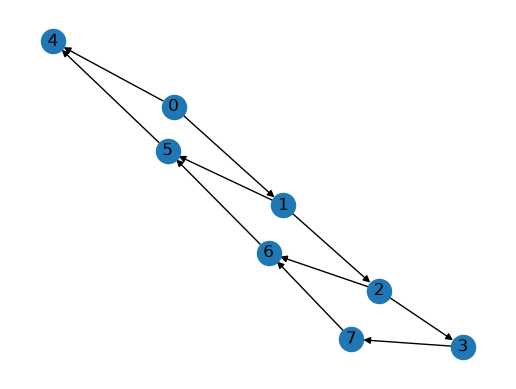

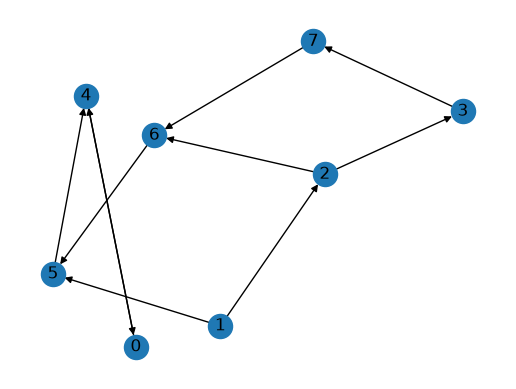

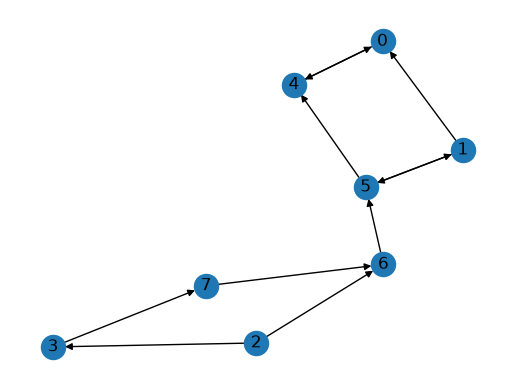

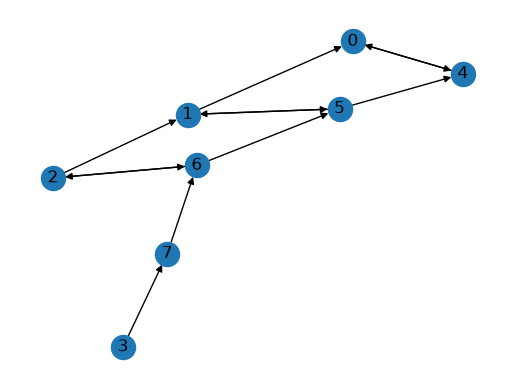

In [102]:
import networkx as nx
import matplotlib.pyplot as plt

example = build_dataset(N=4, N_EXAMPLES=1)

print(len(example), example)
for i in range(0, len(example)):
    fix = plt.subplots()
    g = torch_geometric.utils.to_networkx(example[i], to_undirected=False)
    nx.draw(g, with_labels=True)


# Build torch_geometric dataset from examples

In [103]:
# https://pytorch-geometric.readthedocs.io/en/latest/tutorial/create_dataset.html#frequently-asked-questions
# just create a DataLoader starting from the list of example Data
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader

# train_dataset = build_dataset(N=3, N_EXAMPLES=100)
train_dataset = build_dataset(N=4, N_EXAMPLES=80)# + build_dataset(N=4, N_EXAMPLES=50)
# print("Training dataset: ", train_dataset)

train_loader = DataLoader(train_dataset, batch_size=8)
train2_loader = DataLoader(train_dataset, batch_size=1)
val_loader = DataLoader(build_dataset(N=4, N_EXAMPLES=10), batch_size=1)
# val_loader = DataLoader(build_dataset(N=3, N_EXAMPLES=10) + build_dataset(N=4, N_EXAMPLES=10), batch_size=1, shuffle=True)
test_loader = DataLoader(build_dataset(N=3, N_EXAMPLES=10), batch_size=1)

Building example #0
5 [[1, 0, 0, True, 0.3005484182881938, 0.4896767947556748, 0.6000000000000001, 1, 0, 0, True, 0.3005484182881938, 0.4896767947556748, 0.4, 1, 0, 0, True, 0.3005484182881938, 0.4896767947556748, 0.2, 1, 0, 0, True, 0.3005484182881938, 0.4896767947556748, 0.0, 0, 1, 0, True, 0.0404834601493812, 0.5157868186507127, 0.0, 0, 1, 0, False, 0.0404834601493812, 0.5157868186507127, 0.2, 0, 1, 0, False, 0.0404834601493812, 0.5157868186507127, 0.4, 0, 1, 0, False, 0.0404834601493812, 0.5157868186507127, 0.6000000000000001], [1, 0, 1, True, 0.0404834601493812, 0.5157868186507127, 0.0, 1, 0, 0, True, 0.3005484182881938, 0.4896767947556748, 0.4, 1, 0, 0, True, 0.3005484182881938, 0.4896767947556748, 0.2, 1, 0, 0, True, 0.3005484182881938, 0.4896767947556748, 0.0, 0, 1, 1, False, 0.0404834601493812, 0.5157868186507127, 0.0, 0, 1, 0, True, 0.0404834601493812, 0.5157868186507127, 0.2, 0, 1, 0, False, 0.0404834601493812, 0.5157868186507127, 0.4, 0, 1, 0, False, 0.0404834601493812, 0.5

# Build NN

In [106]:
# https://pytorch-geometric.readthedocs.io/en/latest/modules/nn.html
# https://pytorch-geometric.readthedocs.io/en/latest/get_started/introduction.html
# https://colab.research.google.com/github/Alireza-Akhavan/graph-neural-network/blob/main/07-Graph_Classification_pyg.ipynb#scrollTo=CN3sRVuaQ88l
# https://khairulislam.github.io/GNN/pages/graph/Graph_Classification.html

# regarding the use of position (and generalization to unseen positions): https://github.com/pyg-team/pytorch_geometric/issues/3326
# regarding fully connected graphs and the use of dense layers: https://github.com/pyg-team/pytorch_geometric/issues/964

from torch.nn import Linear
from torch_geometric.nn.conv import GCNConv
from torch_geometric.utils import to_dense_adj, to_dense_batch, to_nested_tensor

import lightning as L
from lightning.pytorch.callbacks import Callback, EarlyStopping
from lightning.pytorch.callbacks.early_stopping import EarlyStoppingReason

class GCN(torch.nn.Module):
    def __init__(self, hidden_dim=64,dropout=0.5):
        super().__init__()
        # All policies consist of 3 hidden layers, with 64 hidden units each and ReLU activation.
        # For attention policies, the number of attention heads were set to 1.
        self.conv1 = GCNConv(2, hidden_dim, normalize=True, add_self_loops=True)
        self.conv2 = GCNConv(hidden_dim, hidden_dim, normalize=True, add_self_loops=True)
        self.conv3 = GCNConv(hidden_dim, hidden_dim, normalize=True, add_self_loops=True)
        self.lin2 = Linear(hidden_dim, 1, bias=True)
        self.dropout = dropout

    def forward(self, data):
        x, edge_index, batch, object_mask = data.x, data.edge_index, data.batch, data.object_mask # batch is the index of the example
        # TODO: re-add this
        # additive measurement noise during training. Probably wrong to be added here but simpler than in batch
        # if self.training:
        #     z = torch.zeros(x.shape)
        #     z[:, 2:] = torch.rand((z[:, 2:].shape))*0.005
        #     x += z

        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv2(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)
        x = self.conv3(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, p=self.dropout, training=self.training)

        x = self.lin2(x)

        # # The output of the GNN policy is K + L dimensional, reshaped into K and L dimensional outputs
        objects_logits = x[data.object_mask]
        objects_batch = batch[data.object_mask]


        goals_logits = x[data.object_mask]
        goals_batch = batch[data.object_mask]

        # since these outputs are interpreted as unnormalized logits, the fill value should be a large negative number to discourage the choice
        objects_dense, objects_mask = to_dense_batch(objects_logits, objects_batch, fill_value=-1e3)
        goals_dense, goals_mask = to_dense_batch(goals_logits, goals_batch, fill_value=-1e3)

        return objects_dense, goals_dense, objects_mask, goals_mask


model = GCN(hidden_dim=32, dropout=0.0).to(device)
model.train()
lr=1e-2
decay = 5e-6
optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=decay)


tacc_obj = []
tacc_goal = []
vacc_obj = []
vacc_goal = []

for epoch in range(3000):
    model.train()
    Loss = torch.zeros((1))
    
    for i, batch in enumerate(train_loader):
        optimizer.zero_grad()
        objects_dense, goals_dense, objects_mask, goals_mask = model(batch)

        y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=-1)
        y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

        y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=-1)
        y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

        # print(objects_dense, objects_dense.shape, y_obj_dense, y_obj_dense.shape)
        
        l1 = F.cross_entropy(objects_dense, y_obj_dense, ignore_index=-1)
        # loss = l1
        l2 = F.cross_entropy(goals_dense, y_goal_dense, ignore_index=-1)
        loss = l1+l2
        Loss += loss * batch.num_graphs

        loss.backward()
        optimizer.step()

    print(f'Training loss (CE): {Loss.item()}')


    def accuracy(loader):
        correct_obj = 0.
        correct_goal = 0.
        dist = {0: 0, 1: 0, 2: 0, 3:0 }

        for i,batch in enumerate(loader):
            objects_dense, goals_dense, objects_mask, goals_mask = model(batch)

            y_obj_dense, _ = to_dense_batch(batch.y[batch.object_mask], batch.batch[batch.object_mask], fill_value=-1)
            y_obj_dense = y_obj_dense.reshape(objects_dense.shape)

            y_goal_dense, _ = to_dense_batch(batch.y[~batch.object_mask], batch.batch[~batch.object_mask], fill_value=-1)
            y_goal_dense = y_goal_dense.reshape(goals_dense.shape)

            # print()
            # print(objects_dense, objects_dense.shape)
            # print(batch.y)
            # print(y_obj_dense, y_obj_dense.shape)
            # # why the hell dim=1 does not work on the y
            # print(torch.argmax(objects_dense, dim=1)==torch.argmax(y_obj_dense, dim=1), torch.argmax(objects_dense, dim=1), torch.argmax(y_obj_dense, dim=1))
            # print()

            # take the argmax for the nodes in each batch
            correct_obj += (torch.argmax(objects_dense, dim=1) == torch.argmax(y_obj_dense, dim=1)).sum().item()
            correct_goal += (torch.argmax(goals_dense, dim=1) == torch.argmax(y_goal_dense, dim=1)).sum().item()
            dist[torch.argmax(objects_dense, dim=1).item()] += 1

        # print(correct_obj, correct_goal)
        acc_obj = correct_obj / i
        acc_goal = correct_goal / i

        return acc_obj, acc_goal, dist

    model.eval()
    
    acc_obj, acc_goal, dist = accuracy(train2_loader)
    print(f'Test Accuracy (objects/goals): {acc_obj:.4f}/{acc_goal:.4f}')
    # print("Distribution of predictions: ", dist)
    tacc_obj.append(acc_obj)
    tacc_goal.append(acc_goal)

    
    acc_obj, acc_goal, dist = accuracy(val_loader)
    print(f'Validation Accuracy (objects/goals): {acc_obj:.4f}/{acc_goal:.4f}')
    # print("Distribution of predictions: ", dist)
    vacc_obj.append(acc_obj)
    vacc_goal.append(acc_goal)

    # break

Training loss (CE): 861.0432739257812
Test Accuracy (objects/goals): 0.0000/0.0000
Validation Accuracy (objects/goals): 0.0000/0.0000
Training loss (CE): 830.72705078125
Test Accuracy (objects/goals): 0.2508/0.2508
Validation Accuracy (objects/goals): 0.2564/0.2564
Training loss (CE): 784.46875
Test Accuracy (objects/goals): 0.5016/0.5016
Validation Accuracy (objects/goals): 0.5128/0.5128
Training loss (CE): 757.634521484375
Test Accuracy (objects/goals): 0.5016/0.5016
Validation Accuracy (objects/goals): 0.5128/0.5128
Training loss (CE): 699.0530395507812
Test Accuracy (objects/goals): 0.7524/0.7524
Validation Accuracy (objects/goals): 0.7692/0.7692
Training loss (CE): 614.7138671875
Test Accuracy (objects/goals): 0.5016/0.5016
Validation Accuracy (objects/goals): 0.5128/0.5128
Training loss (CE): 524.8182983398438
Test Accuracy (objects/goals): 0.5016/0.5016
Validation Accuracy (objects/goals): 0.5128/0.5128
Training loss (CE): 468.1032409667969
Test Accuracy (objects/goals): 0.7524/

KeyboardInterrupt: 

In [ ]:
# Save model
torch.save({
    'model': model,
    'model_state_dict': model.state_dict(),
    'optimizer_state_dict': optimizer.state_dict(),
    'lr': 1e-3,
    'decay': 5e-6,
    'loss': loss,
    'train_dataset': train_dataset
}, "densesageconv_k4_minibatch8_1layer.pth")